# ⏰ Optimal Start & Stop for HVAC: the four PNNL models vs. a one-line learner

**When should a building's air handlers wake up so every room is comfortable right when people arrive, and how early can they shut off at night?**

This notebook builds, explains and benchmarks the four optimal-start models from PNNL's 2024 field study
(Kim, Yu, Lutes & Katipamula, *Applied Thermal Engineering* 257, 124256) side by side with a much simpler
learned-rate model, plus an optimal-stop (coast-down) model. Every algorithm was run closed-loop in the
**NeurIPS 2026 Smart Buildings** simulator: 6 office buildings, 6 climates, 22 thirty-day scenarios, 250 simulations,
almost 23,000 scored air-handler mornings.

<div style="border-left: 6px solid #e6a700; background: #fff8e1; padding: 12px 18px; border-radius: 4px;">

**TL;DR**

* 🏆 **Start winner: the linear-rate EMA**, one learned number per zone (°F recovered per minute). It is the only start
  algorithm that **beats fixed schedules at equal comfort on average (+1.6 % morning energy) while staying in the top tier on
  the simulator's reward** (mean regret −0.065, worst −0.26). It also predicts recovery time best offline (MAE 29 min vs 36-39 min
  for the four PNNL models).
* **PNNL's deployed median-of-four** is a close second on savings beyond schedule (+1.8 %, worst −0.6 %) but has almost
  **twice the reward regret** (−0.12, worst −0.47). **PNNL Model 4** gets the best reward among the learners by starting late,
  at the price of the worst comfort and the worst single scenario (−9.5 %).
* Honest caveat: in this simulator start time is mostly an energy-vs-comfort dial. The learned models save 4-14 % of
  morning energy vs a fixed 2-hour start, but they are late more often (EMA: 43 % of mornings vs 34 %). The gain over a
  well-chosen fixed schedule is small.
* 🏆 **Stop winner: first-order (1R1C) coast-down** with a 0.2 °F guard: **+3.0 % evening energy** for +0.7 °F·min/zone of
  comfort deficit. A constant-drift rule saves more (5.7 %) but wrecks comfort in Phoenix.
</div>

## Table of contents
1. [What optimal start and stop are](#1)
2. [Data, simulator and how we score an algorithm](#2)
3. [PNNL Model 1: quadratic recovery time](#m1)
4. [PNNL Model 2: outdoor-air ratio](#m2)
5. [PNNL Model 3: regression with an outdoor-load term](#m3)
6. [PNNL Model 4: exponential (first-order) approach](#m4)
7. [Why our approach does even better: the linear-rate EMA](#m0)
8. [Optimal stop: first-order coast-down](#stop)
9. [Head-to-head leaderboard and recommendation](#board)
10. [Takeaways, limitations, use it on your own building, references](#end)

<a id="1"></a>
## 1. What optimal start and stop are

Most commercial buildings set back overnight: heating setpoints drop, cooling setpoints rise, and the fans go off.
In the morning the system has to **recover** the zones to the occupied comfort band before people walk in.

* A **fixed schedule** starts every air handler (AHU) the same 60 to 120 minutes early, every day. That's safe on the
  coldest Monday, but on a mild Thursday the building sits comfortable and empty for an hour, burning energy.
* **Optimal start** predicts, each morning, *how long this zone needs to recover today* and starts just that much
  before occupancy. The prediction is learned from past mornings.
* **Optimal stop** is the evening mirror image: near the end of the day, if the zones will drift slowly enough to
  stay comfortable until everyone leaves, turn the AHU off a little early and **coast**.

The whole problem boils down to one number per morning, the lead time:

$$t_{\text{start}} = t_{\text{occupancy}} - \widehat{t}_{\text{recover}}(T_{\text{zone}},\,T_{\text{setpoint}},\,T_{\text{outdoor}},\ \text{history})$$

Start too late and people arrive to a cold office (a **comfort miss**). Start too early and you waste energy (**early waste**).

In [1]:
# Setup: only numpy, pandas, matplotlib (scipy optional). Runs in well under a minute.
import math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 2)

plt.rcParams.update({
    "figure.figsize": (10, 4.6), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "legend.fontsize": 9.5, "legend.frameon": False, "font.size": 10.5,
})

# One name and one color per algorithm, used in every chart.
NAMES = {
    "fixed_60": "Fixed 60 min", "fixed_120": "Fixed 120 min", "fixed_180": "Fixed 180 min",
    "pnnl_m1_quadratic": "PNNL M1 · quadratic", "pnnl_m2_oat_ratio": "PNNL M2 · OAT ratio",
    "pnnl_m3_regression": "PNNL M3 · regression", "pnnl_m4_exponential": "PNNL M4 · exponential",
    "pnnl_deployed_median_split": "PNNL deployed (median of M1-M4)",
    "m0_linear_ema": "Linear-rate EMA (ours)",
    "v6": "G36 learned rate (NeurIPS v6)", "v7": "G36 recovery learner (NeurIPS v7)",
    "sac_trim": "SAC reinforcement learning", "robust_rls": "Robust RLS", "robust_rls_fb": "Robust RLS + feedback",
    "repo_m5_sgd": "SGD regression", "vavrl_static": "Static rate + 15 min",
}
COLORS = {
    "fixed_60": "#c7c7c7", "fixed_120": "#7f7f7f", "fixed_180": "#3f3f3f",
    "pnnl_m1_quadratic": "#1f77b4", "pnnl_m2_oat_ratio": "#ff7f0e", "pnnl_m3_regression": "#2ca02c",
    "pnnl_m4_exponential": "#d62728", "pnnl_deployed_median_split": "#9467bd", "m0_linear_ema": "#e6a700",
    "v6": "#8c564b", "v7": "#e377c2", "sac_trim": "#17becf", "robust_rls": "#bcbd22", "robust_rls_fb": "#98df8a",
    "repo_m5_sgd": "#aec7e8", "vavrl_static": "#c49c94",
}
STOP_NAMES = {"no_early_stop": "No early stop", "first_order_coast": "First-order coast (ours)",
              "vavrl_const_drift": "Constant drift 0.35 °F/h", "v6": "G36 recovery-rate proxy"}
STOP_COLORS = {"no_early_stop": "#7f7f7f", "first_order_coast": "#e6a700", "vavrl_const_drift": "#1f77b4", "v6": "#8c564b"}
K2F = 1.8  # 1 K of temperature difference = 1.8 °F

<a id="2"></a>
## 2. Data, simulator and how we score an algorithm

**Simulator.** The NeurIPS 2026 Smart Buildings challenge uses Google's [Smart Buildings simulator](https://github.com/google/sbsim), a physics-based model of
real office buildings: multiple AHUs, 30 to 85 VAV zones with reheat, real weather, randomized occupancy and a
utility-cost model. Each **scenario** is one building with one 30-day weather strip, stepped every 5 minutes.
Occupied band: 69.5 to 75.0 °F (294 to 297 K), 06:00 to 19:00.

**What changes between runs.** The same ASHRAE Guideline 36 sequence runs the plant in every run. Only two decisions
are swapped: **when each AHU starts its morning warm-up/cool-down**, and **whether it may shut off early** in the evening.
A few "native" baselines run their own full sequence: two of our own NeurIPS competition controllers (v6 with a learned
recovery rate, v7 with a recovery learner and occupancy trees) and a soft actor-critic (SAC) reinforcement-learning agent
trained on the same simulator.

**Learning is online only.** Every model starts empty on day 1 and learns only from mornings it has already seen.
The first 7 days are simulated but not scored (warm-up). No model is trained on the future.

**Metrics** (per AHU per morning, then averaged):

| metric | meaning | better |
|---|---|---|
| **lead** | minutes of warm-up before occupancy | – |
| **late % (1 °F tol.)** | share of mornings a recoverable zone was still more than 1 °F outside the band at occupancy (PNNL's allowable deviation) | lower |
| **unmet** | comfort deficit summed over the first 2 h of occupancy, °F·min per zone | lower |
| **energy saved** | building $ over 4 h before to 2 h after occupancy, vs. a fixed 120-min start on the same day | higher |
| **reward gain** | the simulator's own reward (comfort regret + energy + carbon) over the same window, vs. fixed 120 min | higher |

**Winner criteria.** Start time is mostly a dial between energy and comfort: start later, save energy, lose comfort.
So "saves the most energy" is meaningless on its own. We use three tests:

1. **Savings beyond schedule.** In each scenario, the fixed 60/120/180-minute runs trace the energy-vs-comfort curve
   that any plain schedule can reach. An algorithm only adds value if it saves *more* energy than a fixed schedule that
   delivers the *same* comfort. Positive = beats every fixed schedule.
2. **Reward regret.** Per scenario, the algorithm's reward minus the best algorithm's reward (0 is best).
3. **Worst case.** The worst scenario on both of the above, because a controller that's great on average and terrible in
   one climate is a support call waiting to happen.

In [2]:
# Load the small result files (about 0.4 MB). Works from the repo, from an attached Kaggle dataset, or downloads.
FILES = ["start_ahu_days.csv.gz", "start_days.csv.gz", "runs.csv", "stop_ahu_days.csv.gz", "stop_days.csv.gz",
         "recovery_events.csv.gz", "recovery_traces.csv.gz", "example_morning.csv"]
RAW = "https://raw.githubusercontent.com/bbartling/hvac-optimal-start-math-playground/develop/data/"

def find_data_dir():
    for d in [Path("data"), Path("../data"), *sorted(Path("../input").glob("*")), *sorted(Path("../input").glob("*/data"))]:
        if (d / FILES[0]).exists():
            return d
    return None

DATA = find_data_dir()
def load(name):
    if DATA is not None:
        return pd.read_csv(DATA / name)
    return pd.read_csv(RAW + name)   # fallback: fetch the same file from GitHub

A   = load("start_ahu_days.csv.gz")    # one row per run x scored morning x AHU
D   = load("start_days.csv.gz")        # one row per run x scored morning (building energy and reward)
RUN = load("runs.csv")                 # one row per simulation
SA, SD = load("stop_ahu_days.csv.gz"), load("stop_days.csv.gz")   # dedicated optimal-stop experiment
EV, TR = load("recovery_events.csv.gz"), load("recovery_traces.csv.gz")  # recorded recoveries for model fitting
EX  = load("example_morning.csv")
for c in ["unmet", "unmet_people"]:
    A[c] = A[c] * K2F                  # K·min -> °F·min
print(f"{RUN.shape[0]} simulations | {A.scenario.nunique()} scenarios | {A.scenario.str[:2].nunique()} buildings | "
      f"{A.city.nunique()} climates | {len(A):,} scored AHU-mornings | {EV.shape[0]:,} recorded recoveries")

252 simulations | 22 scenarios | 6 buildings | 6 climates | 23,136 scored AHU-mornings | 1,163 recorded recoveries


### What a morning looks like

Below is one November morning in Denver for one AHU: the shaded band is the comfort band, the line is the average zone
temperature (the ribbon spans the coldest to warmest zone), and the bar marks when warm-up was running. The fixed
schedule starts two hours early and the zones are comfortable well before 06:00. The learned model waits and starts
later, so it uses less energy, but the coldest zone arrives right at the edge of the band.

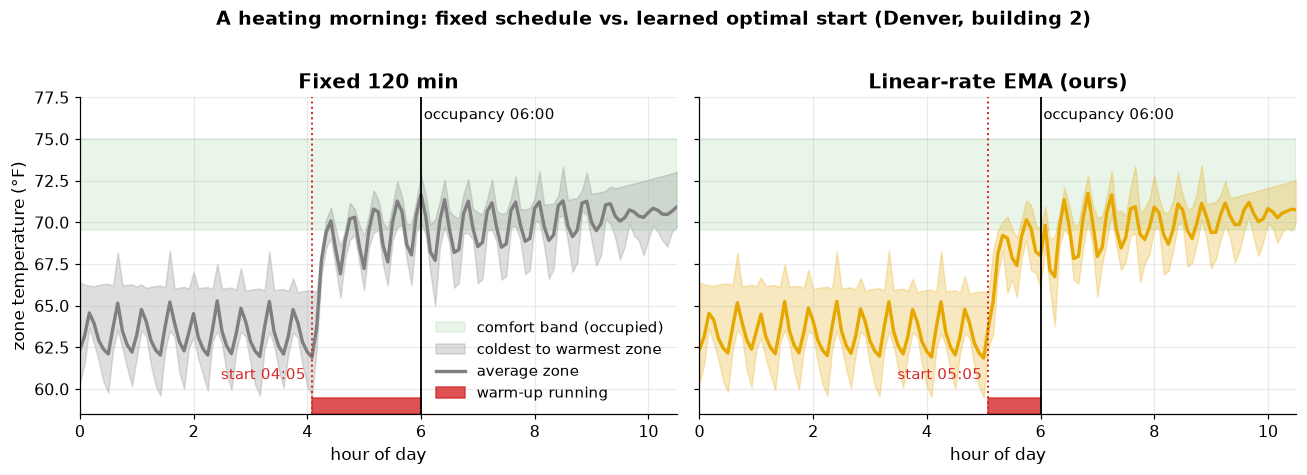

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, st in zip(axes, ["fixed_120", "m0_linear_ema"]):
    e = EX[EX.start == st].copy(); e["time"] = pd.to_datetime(e.time)
    h = e.time.dt.hour + e.time.dt.minute / 60
    ax.axhspan(69.53, 75.0, color="#2ca02c", alpha=0.10, label="comfort band (occupied)")
    ax.fill_between(h, e.zmin_f, e.zmax_f, color=COLORS[st], alpha=0.25, label="coldest to warmest zone")
    ax.plot(h, e.zmean_f, color=COLORS[st], lw=2.2, label="average zone")
    w = h[e.warm == 1]
    if len(w):
        ax.axvspan(w.min(), w.max() + 5 / 60, ymin=0, ymax=0.05, color="#d62728", alpha=0.8, label="warm-up running")
        ax.axvline(w.min(), color="#d62728", ls=":", lw=1.3)
        ax.annotate(f"start {int(w.min()):02d}:{int(round((w.min() % 1) * 60)):02d}", (w.min(), 60.6), xytext=(-4, 0), ha="right",
                    textcoords="offset points", color="#d62728", fontsize=9.5)
    ax.axvline(6, color="k", lw=1.2); ax.text(6.05, 76.2, "occupancy 06:00", fontsize=9.5)
    ax.set_title(NAMES[st]); ax.set_xlabel("hour of day"); ax.set_xlim(0, 10.5); ax.set_ylim(58.5, 77.5)
axes[0].set_ylabel("zone temperature (°F)"); axes[0].legend(loc="lower right")
fig.suptitle("A heating morning: fixed schedule vs. learned optimal start (Denver, building 2)", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

### Shared scoring helpers

Every algorithm section uses the same two helpers: one scores a closed-loop run (lateness, comfort, energy and reward
against a fixed 120-minute start on the same day), the other replays recorded mornings offline so we can plot predicted
vs. actual recovery time.

In [4]:
def q90(x): return float(np.nanpercentile(x, 90)) if len(x) else np.nan

# Energy / reward paired with the fixed-120 run on the same scenario and date.
_base = D[D.start == "fixed_120"][["scenario", "date", "morning_energy", "morning_reward"]].rename(
    columns={"morning_energy": "e0", "morning_reward": "r0"})
DP = D.merge(_base, on=["scenario", "date"])
DP["saved_pct"] = 100 * (DP.e0 - DP.morning_energy) / DP.e0
DP["reward_gain"] = DP.morning_reward - DP.r0

def score(by=("start",), a=A, d=DP):
    by = list(by)
    s = a.groupby(by).agg(mornings=("lead", "size"), lead_p50=("lead", "median"),
                          late_pct=("late_tol", lambda x: 100 * (x > 0).mean()), late_p90=("late_tol", q90),
                          unmet=("unmet", "mean"))
    e = d.groupby(by).agg(saved_pct=("saved_pct", "mean"), reward_gain=("reward_gain", "mean"))
    return s.join(e)

def F(t, default="{:.1f}", **over):
    # one formatter per column (behaves the same on every pandas version)
    cols = t.columns if hasattr(t, "columns") else t.index
    return {c: over.get(c, default) for c in cols}

COLS = {"mornings": "AHU-mornings", "lead_p50": "lead p50 (min)", "late_pct": "late % (1 °F tol.)",
        "late_p90": "late p90 (min)", "unmet": "unmet (°F·min/zone)", "saved_pct": "energy saved vs fixed 120 (%)",
        "reward_gain": "reward gain vs fixed 120"}
def show(t, caption=None, fmt=None):
    t = t.rename(columns=COLS).rename(index=lambda i: NAMES.get(i, i))
    f = F(t, fmt or "{:.1f}")
    f.update({c: v for c, v in {"AHU-mornings": "{:,.0f}", "reward gain vs fixed 120": "{:+.3f}"}.items() if c in t})
    st = t.style.format(f, na_rep="–")
    if caption: st = st.set_caption(caption)
    display(st)

# ---- offline replay of recorded recoveries ----------------------------------------------------------
# Each event: one AHU's critical (furthest-from-setpoint) zone on one morning of a fixed-180 run, with its
# trajectory from the moment warm-up began (°F, 5-min samples) until it reached the setpoint.
TRAJ = {k: g[["minute", "temp_f"]].to_numpy() for k, g in TR.groupby("event")}
EV = EV.sort_values(["scenario", "ahu", "date"]).reset_index(drop=True)

def deficit(mode, temp, target): return max(0.0, target - temp) if mode == "heat" else max(0.0, temp - target)

def replay(make_model, max_lead=180.0):
    """Feed each AHU's mornings to a fresh model in date order: predict first, then learn. Returns predictions."""
    out = []
    for _, g in EV.groupby(["scenario", "ahu"], sort=False):
        m = make_model()
        for e in g.itertuples():
            tr = TRAJ[e.event]
            p = m.predict(e.mode, e.start_temp_f, e.target_f, e.oat_f, e.post_weekend)
            p = max_lead if p is None else float(np.clip(p, 0, max_lead))
            # where would the zone be if we had started p minutes early? (for M3's day-to-day correction)
            k = min(int(round(p / 5)), len(tr) - 1)
            short = deficit(e.mode, tr[k, 1], e.target_f) if p < tr[-1, 0] or np.isnan(e.minutes_to_target) else 0.0
            if np.isfinite(e.minutes_to_target):
                m.update(dict(mode=e.mode, start=e.start_temp_f, target=e.target_f, oat=e.oat_f, oat_mean=e.oat_mean_f,
                              t=e.minutes_to_target, traj=tr, arrival_error=short))
            out.append((e.event, e.city, e.mode, p, e.minutes_to_target))
    return pd.DataFrame(out, columns=["event", "city", "mode", "pred", "actual"])

def replay_stats(r):
    ok = r.dropna(subset=["actual"])
    err = ok.pred - ok.actual
    return pd.Series({"recoveries": len(ok), "MAE (min)": err.abs().mean(), "bias (min)": err.mean(),
                      "late starts %": 100 * (err < -5).mean(), "within ±15 min %": 100 * (err.abs() <= 15).mean()})

def show_replay(key):
    t = replay_stats(REPLAY[key]).to_frame(NAMES[key]).T
    display(t.style.format(F(t, "{:.1f}", recoveries="{:,.0f}")).set_caption("Offline replay of recorded recoveries (predict, then learn)"))

def pnnl_ema(values):
    """PNNL's deployed EMA over a window of daily parameters: newest weighted most, smoothing min(1, 4/(n+1))."""
    n = len(values); s = min(1.0, 4.0 / (n + 1)); rev = values[::-1]
    return sum(rev[i] * s * (1 - s) ** i for i in range(n)) + rev[-1] * (1 - s) ** n

def minutes_per_first_degree(ev, degree=1.0):
    sign = 1 if ev["mode"] == "heat" else -1
    for t, temp in ev["traj"]:
        gained = sign * (temp - ev["start"])
        if t > 0 and gained >= degree:
            return t / gained
    return None

def evaluation_plots(key, rep):
    """Two panels: offline predicted vs actual recovery time, closed-loop arrival error vs fixed 120."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3))
    ok = rep.dropna(subset=["actual"])
    for mode, mk in [("heat", "o"), ("cool", "^")]:
        s = ok[ok["mode"] == mode]
        a1.scatter(s.actual, s.pred, s=14, alpha=0.45, marker=mk, color=COLORS[key], label=f"{mode}ing mornings")
    lim = max(60, np.nanpercentile(ok.actual, 99), np.nanpercentile(ok.pred, 99)) * 1.05
    a1.plot([0, lim], [0, lim], "k--", lw=1, label="perfect prediction")
    a1.set_xlim(0, lim); a1.set_ylim(0, lim); a1.legend(loc="upper left")
    a1.set_xlabel("actual recovery time (min)"); a1.set_ylabel("predicted recovery time (min)")
    a1.set_title("Offline replay: predicted vs. actual")
    bins = np.arange(-120, 245, 10)
    for k, alpha in [("fixed_120", 0.35), (key, 0.75)]:
        x = A[A.start == k].arrival.clip(-120, 240)
        a2.hist(x, bins=bins, density=True, alpha=alpha, color=COLORS[k], label=NAMES[k])
    a2.axvline(0, color="k", lw=1)
    a2.set_xlabel("arrival error (min): < 0 early (wasted run), > 0 late; last bar = 4 h or more")
    a2.set_ylabel("share of AHU-mornings"); a2.set_title("Closed loop: when the last zone got comfortable"); a2.legend(loc="upper center")
    a2.yaxis.set_major_formatter(PercentFormatter(xmax=0.1, decimals=0))
    plt.tight_layout(); plt.show()

def climate_table(key):
    t = score(["start", "city"]).loc[[key, "fixed_120"]].reset_index()
    t["algorithm"] = t.start.map(NAMES)
    t = t.set_index(["city", "algorithm"]).drop(columns="start").sort_index()
    show(t, caption=f"{NAMES[key]} vs. a fixed 120-min start, by climate (closed loop)")

<a id="m1"></a>
## 3. PNNL Model 1: quadratic recovery time

### How it works
**Intuition.** The bigger the temperature gap at start-up, the longer recovery takes, and it grows faster than linearly
because the zone's heat loss grows as it warms. Model 1 ignores the weather entirely; it only looks at the gap.

$$\widehat{t} = a\,\big(T_{sp} - T_{z,0}\big)^2 + b$$

* $b$ = minutes per degree over the **first** degree of recovery (start-up lag: fans spinning up, coils warming).
* $a$ = the extra curvature: from yesterday's actual time $t_{act}$ and gap $\Delta T_0$, $a = (t_{act} - b)/\Delta T_0^2$
  (if $t_{act} - b < 1$, PNNL uses $a = t_{act}/(10\,\Delta T_0)$).

**Inputs:** zone temperature, occupied setpoint. **Fitting:** each morning yields one $(a, b)$ pair; the last 8 days are
kept and blended with PNNL's exponential moving average (newest day weighted most).

**Worked example.** With $b = 6$ min and $a = 1.5$ min/°F², a 5 °F gap needs $1.5 \cdot 25 + 6 = 43.5$ minutes.

**When it works / when it fails.** Works where recovery is dominated by the zone itself (interior zones, mild weather).
Fails when the weather changes overnight: a cold snap makes recovery slower at the same gap, and Model 1 can't see it.

In [5]:
class PNNLModel1:
    name = "pnnl_m1_quadratic"
    def __init__(self, window=8): self.a, self.b, self.w = {"heat": [], "cool": []}, {"heat": [], "cool": []}, window
    def predict(self, mode, temp, target, oat, post_weekend=False):
        d = deficit(mode, temp, target)
        if d <= 0: return 0.0
        if not self.a[mode]: return None                 # no history yet -> planner uses the max lead
        return pnnl_ema(self.a[mode]) * d * d + pnnl_ema(self.b[mode])
    def update(self, ev):
        t, d0, b = ev["t"], deficit(ev["mode"], ev["start"], ev["target"]), minutes_per_first_degree(ev)
        if not t or d0 <= 0 or b is None: return
        a = (t - b) / d0 ** 2 if t - b >= 1 else t / (10 * d0)
        self.a[ev["mode"]] = (self.a[ev["mode"]] + [a])[-self.w:]
        self.b[ev["mode"]] = (self.b[ev["mode"]] + [b])[-self.w:]

m = PNNLModel1(); print("worked example:", 1.5 * 5 ** 2 + 6, "min")
REPLAY = {"pnnl_m1_quadratic": replay(PNNLModel1)}

worked example: 43.5 min


### Evaluation

,recoveries,MAE (min),bias (min),late starts %,within ±15 min %
PNNL M1 · quadratic,"1,033",38.9,10.8,23.2,54.5


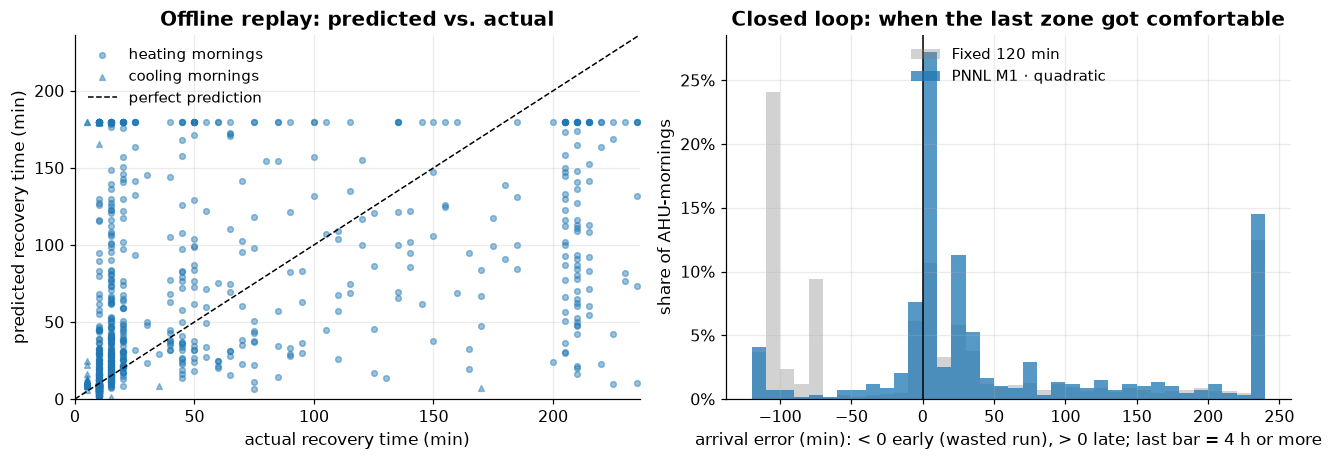

In [6]:
key = "pnnl_m1_quadratic"
show_replay(key)
evaluation_plots(key, REPLAY[key]); climate_table(key)

**Strengths:** two parameters, no weather sensor, easy to explain. **Weaknesses:** blind to outdoor temperature; the
first-degree rate $b$ is noisy when the zone barely moves in the first few samples. In closed loop it starts fairly early
(lead around two hours), so it rarely saves much over a fixed schedule.

<a id="m2"></a>
## 4. PNNL Model 2: outdoor-air ratio

### How it works
**Intuition.** Learn yesterday's recovery **rate** (degrees per minute), then scale it by how much colder (or hotter) it
is today than yesterday, relative to a "design" outdoor temperature at which the unit would have to run nonstop.

$$\widehat{t} = \frac{T_{sp} - T_{z,0}}{\alpha}\cdot\frac{T_{o,ref} - T_{o}^{\,k-1}}{T_{o,ref} - T_{o}^{\,k}}, \qquad \alpha = \frac{\Delta T_{k-1}}{t_{k-1}}$$

$T_{o,ref}$ = 0 °F for heating and 100 °F for cooling (the ASHRAE values used in the paper).

**Inputs:** zone temperature, setpoint, outdoor air temperature. **Fitting:** daily $\alpha$ and the training-day OAT,
8-day window, PNNL EMA. We add one guard the paper doesn't have: the ratio is clipped to [0.25, 4] so an OAT reading near
the reference can't command a 0- or 1000-minute start (Fairbanks drops below 0 °F).

**Worked example.** Yesterday: 4 °F recovered in 40 min, so $\alpha = 0.1$ °F/min, at 30 °F outside. Today: a 5 °F gap
at 15 °F outside. Ratio $(0-30)/(0-15) = 2$, so $\widehat{t} = 5/0.1 \cdot 2 = 100$ minutes.

**When it works / when it fails.** Good for lightweight, perimeter-dominated buildings where the weather drives the load.
Fails when OAT is close to the reference (the ratio explodes) and in heavy buildings where thermal mass, not OAT, dominates.

In [7]:
class PNNLModel2:
    name = "pnnl_m2_oat_ratio"
    REF = {"heat": 0.0, "cool": 100.0}
    def __init__(self, window=8): self.rate, self.oat, self.w = {"heat": [], "cool": []}, {"heat": [], "cool": []}, window
    def predict(self, mode, temp, target, oat, post_weekend=False):
        d = deficit(mode, temp, target)
        if d <= 0: return 0.0
        if not self.rate[mode]: return None
        ref, prev = self.REF[mode], pnnl_ema(self.oat[mode])
        ratio = (ref - prev) / (ref - oat) if abs(ref - oat) > 1e-6 else 1.0
        ratio = 1.0 if not np.isfinite(ratio) or ratio <= 0 else float(np.clip(ratio, 0.25, 4.0))
        return d / pnnl_ema(self.rate[mode]) * ratio
    def update(self, ev):
        d0 = deficit(ev["mode"], ev["start"], ev["target"])
        if not ev["t"] or d0 <= 0: return
        self.rate[ev["mode"]] = (self.rate[ev["mode"]] + [d0 / ev["t"]])[-self.w:]
        self.oat[ev["mode"]] = (self.oat[ev["mode"]] + [ev["oat_mean"]])[-self.w:]

print("worked example:", 5 / 0.1 * (0 - 30) / (0 - 15), "min")
REPLAY["pnnl_m2_oat_ratio"] = replay(PNNLModel2)

worked example: 100.0 min


### Evaluation

,recoveries,MAE (min),bias (min),late starts %,within ±15 min %
PNNL M2 · OAT ratio,"1,033",36.2,0.3,26.1,61.5


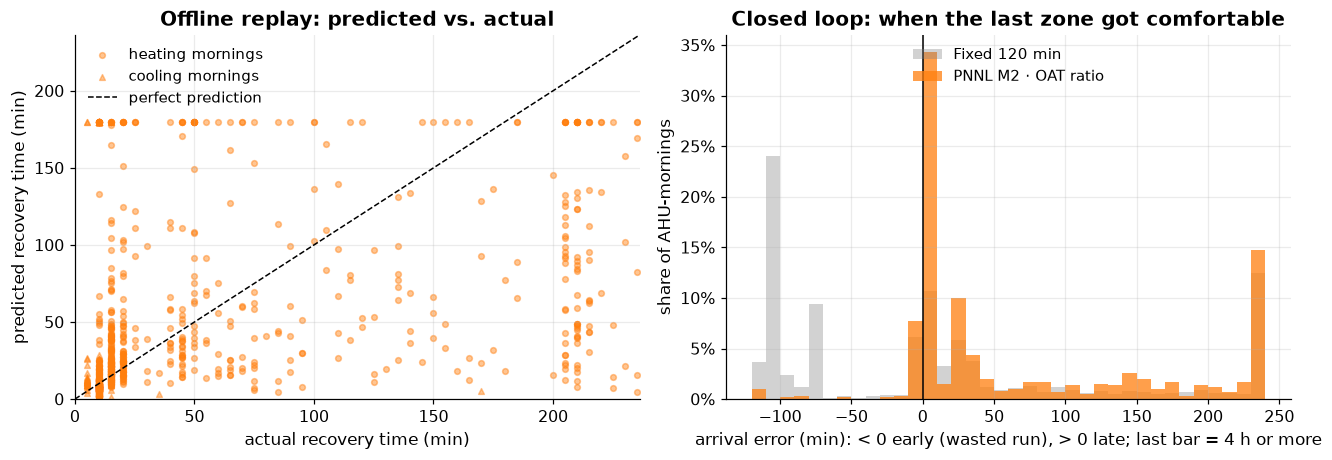

In [8]:
key = "pnnl_m2_oat_ratio"
show_replay(key)
evaluation_plots(key, REPLAY[key]); climate_table(key)

**Strengths:** the only PNNL model that reacts to a change in weather from one day to the next. **Weaknesses:** the ratio
is unstable near the reference temperature and amplifies OAT sensor noise. In closed loop it trades comfort for energy
much like a 60-minute schedule.

<a id="m3"></a>
## 5. PNNL Model 3: regression with an outdoor-load term

### How it works
**Intuition.** Recovery time = a part proportional to the gap, plus a part proportional to *gap × how hard the weather is
pushing back*, plus a self-correcting nudge if yesterday's start was late or early.

$$\widehat{t} = a\,\Delta T + \frac{b}{c}\,\Delta T\,\big(T_{sp} - T_o\big) + d$$

* $a$ = minutes per degree over the first degree (like Model 1's $b$).
* $b = (t_{act} - a\,\Delta T_0)\,c\,/\,\big(\Delta T_0 (T_{sp} - T_o)\big)$, clipped at 0; $c = 10$ is PNNL's scale constant.
* $d$ = day-to-day correction: $+5$ min if yesterday the zone was more than 1 °F short at occupancy, $-5$ min if it
  overshot by more than 1 °F, reset to 0 if $|d|$ exceeds 60 min.

**Inputs:** zone temperature, setpoint, OAT, yesterday's arrival error. **Fitting:** 8-day windows for $a$ and $b$ with the
PNNL EMA; $d$ integrates the arrival feedback.

**Worked example.** $a = 6$ min/°F, $b = 0.5$, gap 5 °F, OAT 30 °F, setpoint 70 °F: $6\cdot5 + 0.05\cdot5\cdot40 + 0 = 40$ min.

**When it works / when it fails.** The paper found it the most accurate in the field. It needs a few mornings for $b$ to settle,
and the $\pm5$-minute correction is slow to react when the error is large (a Monday after a cold weekend).

In [9]:
class PNNLModel3:
    name = "pnnl_m3_regression"
    def __init__(self, window=8, c=10.0, step=5.0, reset=60.0, band=1.0):
        self.a, self.b, self.d = {"heat": [], "cool": []}, {"heat": [], "cool": []}, {"heat": 0.0, "cool": 0.0}
        self.w, self.c, self.step, self.reset, self.band = window, c, step, reset, band
    @staticmethod
    def load(mode, target, oat): return (target - oat) if mode == "heat" else (oat - target)
    def predict(self, mode, temp, target, oat, post_weekend=False):
        dT = deficit(mode, temp, target)
        if dT <= 0: return 0.0
        if not self.a[mode]: return None
        b = pnnl_ema(self.b[mode]) if self.b[mode] else 0.0
        return pnnl_ema(self.a[mode]) * dT + b * dT * max(0.0, self.load(mode, target, oat)) / self.c + self.d[mode]
    def update(self, ev):
        mode, t, d0 = ev["mode"], ev["t"], deficit(ev["mode"], ev["start"], ev["target"])
        if not t or d0 <= 0: return
        a = minutes_per_first_degree(ev) or t / d0
        L = self.load(mode, ev["target"], ev["oat"])
        b = max(0.0, (t - a * d0) * self.c / (d0 * L)) if L > 0.5 else 0.0
        self.a[mode], self.b[mode] = (self.a[mode] + [a])[-self.w:], (self.b[mode] + [b])[-self.w:]
        err, dd = ev["arrival_error"], self.d[mode]
        dd += self.step if err > self.band else (-self.step if err < -self.band else 0.0)
        self.d[mode] = 0.0 if abs(dd) > self.reset else dd

print("worked example:", 6 * 5 + 0.5 / 10 * 5 * 40, "min")
REPLAY["pnnl_m3_regression"] = replay(PNNLModel3)

worked example: 40.0 min


### Evaluation

,recoveries,MAE (min),bias (min),late starts %,within ±15 min %
PNNL M3 · regression,"1,033",39.1,12.8,26.9,51.5


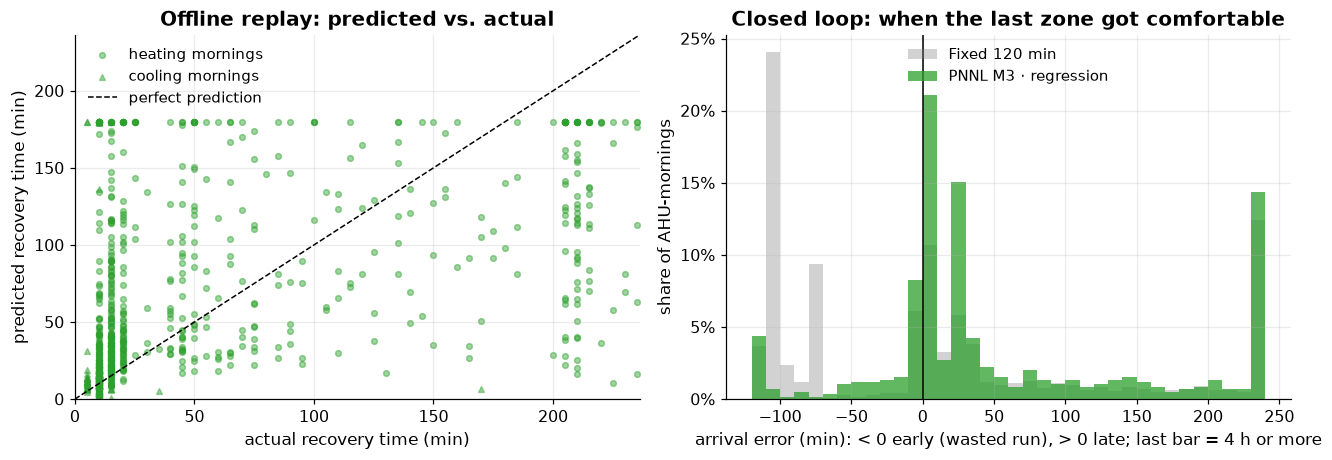

In [10]:
key = "pnnl_m3_regression"
show_replay(key)
evaluation_plots(key, REPLAY[key]); climate_table(key)

**Strengths:** physically motivated (it is the linearised first-order zone model from the paper's Eq. 10), uses the weather,
and corrects itself from arrival feedback. **Weaknesses:** the outdoor term makes it start early in cold weather, so it behaves
close to a fixed two-hour schedule; the slow $\pm5$-minute correction can't fix a big miss in one day.

<a id="m4"></a>
## 6. PNNL Model 4: exponential (first-order) approach

### How it works
**Intuition.** Treat the temperature error as decaying exponentially once the unit starts: each minute the remaining gap
shrinks by a constant factor $c$. Recovery is done when the gap is inside the allowable deviation.

$$\widehat{t} = \frac{\ln(a/b)}{\ln c}, \qquad c = \frac{\sum_i e_{i-1}e_i}{\sum_i e_{i-1}^2}$$

* $a$ = allowable deviation (1 °F), $b$ = current gap, $e_i$ = gap at sample $i$ of yesterday's recovery.
* $c$ is a least-squares fit of $e_i \approx c\,e_{i-1}$ over yesterday's trajectory, converted to a per-minute factor.

**Inputs:** zone temperature and setpoint only, but it uses the whole recovery trajectory. **Fitting:** one $c$ per morning,
8-day window, PNNL EMA. Before any history, $c = e^{-1/190}$.

**Worked example.** Gap 5 °F, $c = 0.97$ per minute: $\ln(1/5)/\ln(0.97) = 52.8$ min.

**When it works / when it fails.** Elegant and needs no weather data. But it aims for *within 1 °F* rather than the setpoint,
and a fast exponential start (big fans, small zones) fits a small $c$ that predicts very short warm-ups. In this simulator it
starts late on most mornings.

In [11]:
class PNNLModel4:
    name = "pnnl_m4_exponential"
    def __init__(self, window=8, deviation=1.0, earliest=180.0, latest=10.0):
        self.c, self.w, self.dev, self.c0 = {"heat": [], "cool": []}, window, deviation, math.exp(-1 / (earliest + latest))
    def predict(self, mode, temp, target, oat, post_weekend=False):
        err = deficit(mode, temp, target)
        if err <= self.dev: return 0.0
        c = float(np.clip(pnnl_ema(self.c[mode]) if self.c[mode] else self.c0, 0.001, 0.999))
        return math.log(self.dev / err) / math.log(c)
    def update(self, ev):
        tr = ev["traj"]
        if len(tr) < 3: return
        dt = float(np.median(np.diff(tr[:, 0])))
        e = np.array([deficit(ev["mode"], x, ev["target"]) for x in tr[:, 1]])
        sxy, sxx = float((e[:-1] * e[1:]).sum()), float((e[:-1] ** 2).sum())
        if sxx <= 0 or sxy <= 0: return
        c_min = float(np.clip(sxy / sxx, 0.001, 0.999)) ** (1 / dt)
        self.c[ev["mode"]] = (self.c[ev["mode"]] + [float(np.clip(c_min, 0.001, 0.999))])[-self.w:]

print("worked example:", round(math.log(1 / 5) / math.log(0.97), 1), "min")
REPLAY["pnnl_m4_exponential"] = replay(PNNLModel4)

worked example: 52.8 min


### Evaluation

,recoveries,MAE (min),bias (min),late starts %,within ±15 min %
PNNL M4 · exponential,"1,033",35.8,-22.6,58.4,69.3


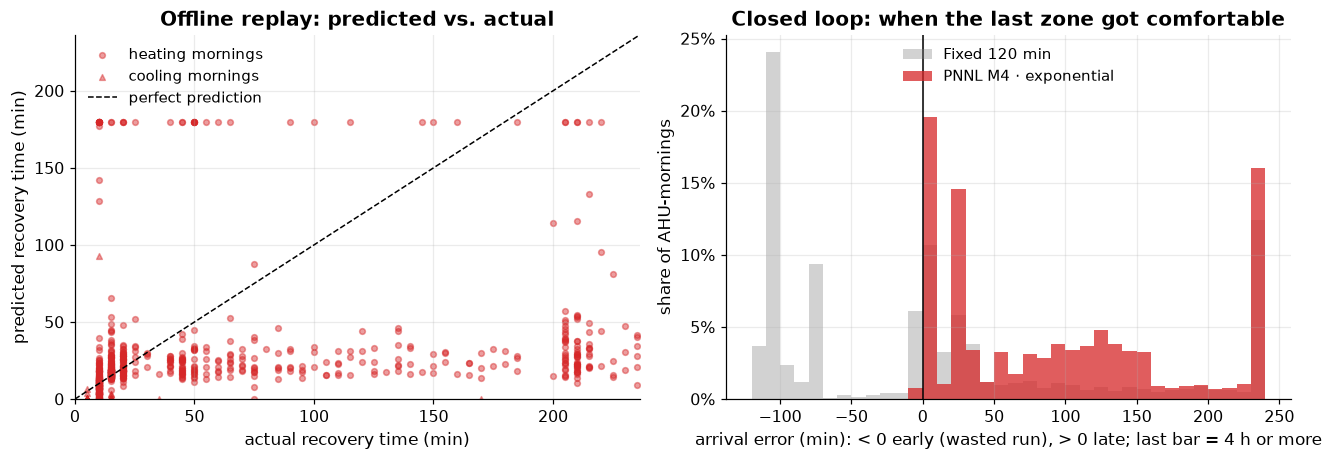

In [12]:
key = "pnnl_m4_exponential"
show_replay(key)
evaluation_plots(key, REPLAY[key]); climate_table(key)

**Strengths:** the biggest energy savings of any algorithm, and the best simulator reward among the learners, because it
starts late. **Weaknesses:** that's mostly lateness, not intelligence: it is late on far more mornings than a fixed schedule,
with the worst comfort of the whole field and the worst single-scenario result (see the leaderboard).

### PNNL's deployed version: median of the four
PNNL's field agent doesn't pick one model: it runs all four and uses the **median** prediction, with a separate set trained
only on post-weekend days (the paper's "Monday problem"). We benchmark that too, as `PNNL deployed (median of M1-M4)`.

<a id="m0"></a>
## 7. Why our approach does even better: the linear-rate EMA

### How it works
**Intuition.** Forget curves and weather ratios. Track one number per mode, the zone's **recovery rate** in °F per minute,
and update it a little every morning. Predicted time is just the gap divided by the rate.

$$\widehat{t} = \frac{T_{sp} - T_{z,0}}{R}, \qquad R \leftarrow R + w\left(\frac{\Delta T_0}{t_{act}} - R\right), \quad w = 0.2$$

**What it does differently from the PNNL models**
* **One parameter, one update.** No windows, no quadratic term to go unstable, no OAT ratio to explode.
* **It uses the full gap-to-setpoint time,** not the first degree only, so start-up lag is folded into the rate.
* **A slow EMA ($w=0.2$) averages out day-to-day noise** but still follows seasons within a week or so.
* It is the same kind of logic that ships in common building-automation "optimal start" blocks, so it is easy to deploy.

**Worked example.** $R = 0.1$ °F/min and a 5 °F gap: 50 minutes. Today it actually took 40 min (rate 0.125), so
$R \leftarrow 0.1 + 0.2(0.125-0.1) = 0.105$ °F/min.

**When it works / when it fails.** Works well wherever recovery speed is fairly steady (most mornings in most climates).
It has no weather term, so a sudden cold snap or a cold-soaked Monday can make it late; a fixed safety margin or a
post-weekend factor is the natural add-on.

In [13]:
class LinearRateEMA:
    name = "m0_linear_ema"
    def __init__(self, rate=0.1, w=0.2, min_rate=0.005): self.R, self.w, self.min = {"heat": rate, "cool": rate}, w, min_rate
    def predict(self, mode, temp, target, oat, post_weekend=False):
        return deficit(mode, temp, target) / max(self.min, self.R[mode])
    def update(self, ev):
        d0 = deficit(ev["mode"], ev["start"], ev["target"])
        if ev["t"] and d0 > 0:
            self.R[ev["mode"]] = max(self.min, self.R[ev["mode"]] + self.w * (d0 / ev["t"] - self.R[ev["mode"]]))

m = LinearRateEMA(); print("worked example:", m.predict("heat", 65, 70, 30), "min ->", end=" ")
m.update(dict(mode="heat", start=65, target=70, t=40)); print(f"rate {m.R['heat']:.3f} °F/min")
REPLAY["m0_linear_ema"] = replay(LinearRateEMA)

worked example: 50.0 min -> rate 0.105 °F/min


### Evaluation

,recoveries,MAE (min),bias (min),late starts %,within ±15 min %
Linear-rate EMA (ours),"1,033",28.9,-14.1,25.8,62.1


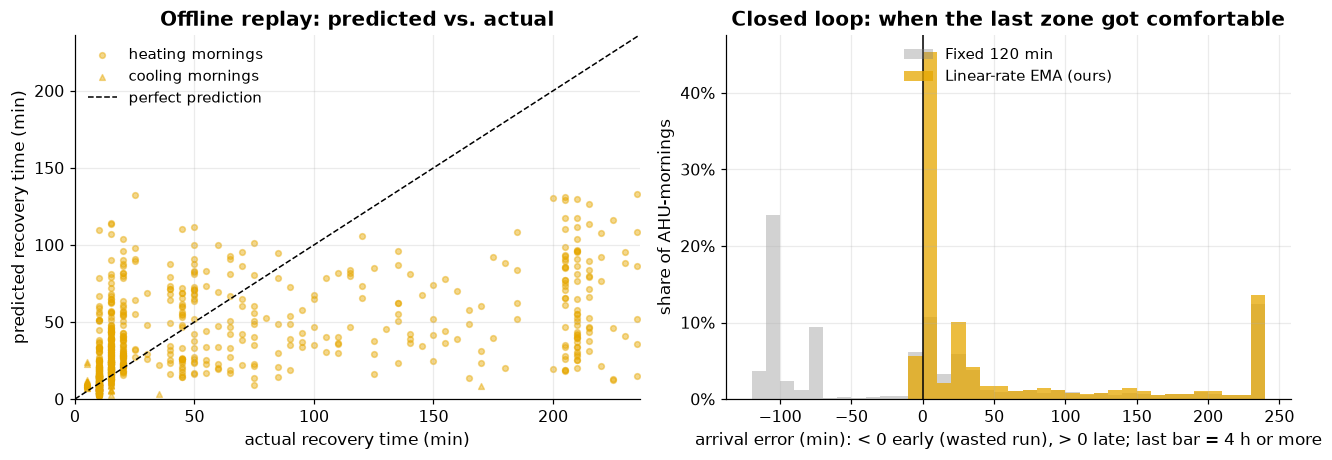

In [14]:
key = "m0_linear_ema"
show_replay(key)
evaluation_plots(key, REPLAY[key]); climate_table(key)

### Head-to-head with the PNNL models

The fair comparison is the **energy-vs-comfort trade-off**, not raw savings. In each scenario the three fixed schedules
(60, 120, 180 min) define the curve any schedule can reach. The chart puts every algorithm on that map: up = more energy
saved, left = better comfort. Points **above the grey schedule curve** beat every fixed schedule.

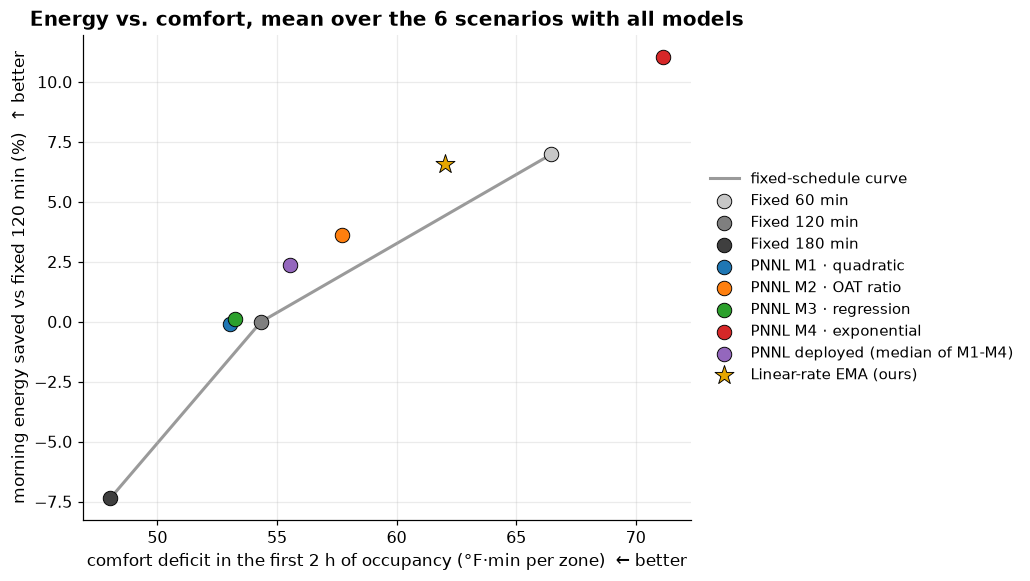

,savings beyond schedule % (mean),… worst scenario,reward regret (mean),late % (1 °F tol.),unmet (°F·min/zone)
start,,,,,
Linear-rate EMA (ours),0.73,-0.78,-0.09,49.74,62.03
PNNL M1 · quadratic,0.29,-1.09,-0.18,45.92,53.05
PNNL M2 · OAT ratio,0.49,-0.58,-0.15,47.44,57.71
PNNL M3 · regression,0.33,-1.31,-0.17,43.69,53.24
PNNL M4 · exponential,0.28,-4.02,-0.04,52.17,71.14
PNNL deployed (median of M1-M4),0.67,-0.55,-0.15,46.37,55.56
Fixed 120 min,0.00,0.00,-0.08,36.34,54.34


In [15]:
# Per-scenario table used by the leaderboard as well.
P = score(["scenario", "start"]).reset_index()

def beyond_schedule(g):
    """Energy % saved beyond the fixed-schedule curve at equal comfort, per scenario."""
    anc = g[g.start.isin(["fixed_60", "fixed_120", "fixed_180"])].sort_values("unmet")
    if len(anc) < 2: return pd.Series(np.nan, index=g.index)
    u, e = anc.unmet.to_numpy(), anc.saved_pct.to_numpy()
    def sched(x):
        i = 0 if x <= u[0] else (len(u) - 2 if x >= u[-1] else int(np.searchsorted(u, x) - 1))
        return e[i] + (e[i + 1] - e[i]) * (x - u[i]) / (u[i + 1] - u[i])
    return g.saved_pct - g.unmet.map(sched)

P["beyond"] = P.groupby("scenario", group_keys=False).apply(beyond_schedule)
P["regret"] = P.reward_gain - P.groupby("scenario").reward_gain.transform("max")

# Trade-off map on the 6 scenarios where every PNNL model and all three schedules were run.
common = P[P.start == "pnnl_m1_quadratic"].scenario
sub = P[P.scenario.isin(common)]
M = sub.groupby("start")[["unmet", "saved_pct"]].mean()
fig, ax = plt.subplots(figsize=(9.5, 5.4))
sch = M.loc[["fixed_180", "fixed_120", "fixed_60"]]
ax.plot(sch.unmet, sch.saved_pct, "-", color="#9a9a9a", lw=2, zorder=1, label="fixed-schedule curve")
for k in ["fixed_60", "fixed_120", "fixed_180", "pnnl_m1_quadratic", "pnnl_m2_oat_ratio", "pnnl_m3_regression",
          "pnnl_m4_exponential", "pnnl_deployed_median_split", "m0_linear_ema"]:
    x, y = M.loc[k]
    ax.scatter(x, y, s=170 if k == "m0_linear_ema" else 90, color=COLORS[k], edgecolor="k", lw=0.6, zorder=3,
               marker="*" if k == "m0_linear_ema" else "o", label=NAMES[k])
ax.set_xlabel("comfort deficit in the first 2 h of occupancy (°F·min per zone)  ← better")
ax.set_ylabel("morning energy saved vs fixed 120 min (%)  ↑ better")
ax.set_title(f"Energy vs. comfort, mean over the {len(common)} scenarios with all models")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.tight_layout(); plt.show()

H = sub.groupby("start").agg(beyond=("beyond", "mean"), worst=("beyond", "min"), regret=("regret", "mean"),
                             late=("late_pct", "mean"), unmet=("unmet", "mean"))
H = H.loc[["m0_linear_ema", "pnnl_m1_quadratic", "pnnl_m2_oat_ratio", "pnnl_m3_regression", "pnnl_m4_exponential",
           "pnnl_deployed_median_split", "fixed_120"]]
display(H.rename(index=NAMES, columns={"beyond": "savings beyond schedule % (mean)", "worst": "… worst scenario",
        "regret": "reward regret (mean)", "late": "late % (1 °F tol.)", "unmet": "unmet (°F·min/zone)"})
        .pipe(lambda t: t.style.format(F(t, "{:.2f}"))).set_caption(f"Head-to-head on the {len(common)} common scenarios"))

**Verdict.** On the six scenarios where all four PNNL models ran, the linear-rate EMA has the **highest savings beyond a fixed
schedule** (+0.73 % vs +0.28 to +0.67 % for the PNNL models and their median) and better reward regret than Models 1-3 and the
median (−0.09 vs −0.15 to −0.18). It is also the most accurate model in the offline replay (MAE 29 min vs 36-39 min).

It is **not** better on everything, and we won't claim it is:
* **PNNL Model 4 earns more simulator reward** (regret −0.04), because the reward weights energy heavily and Model 4 starts very
  late. It pays for it with the worst comfort deficit and a −4 % worst case even on these six scenarios.
* **Models 1-3 are more comfortable** (fewer late mornings) simply because they start earlier: they sit *on* the
  schedule curve, not above it.
* **The PNNL median has a slightly better worst case** (−0.55 % vs −0.78 %).

So the EMA's edge is robustness and simplicity: one parameter, no unstable ratio, and it lands above the schedule curve in
most scenarios.

<a id="stop"></a>
## 8. Optimal stop: first-order coast-down

### How it works
**Intuition.** Near the end of the day, ask: *if I switch this AHU off now, will every zone stay comfortable until the
building empties?* If yes, stop. To answer it, learn how each zone drifts while the fan is off.

The zone is modelled as one thermal resistance and one capacitance (1R1C):

$$\frac{dT}{dt} = a\,(T_o - T) + b + c\cdot\text{occupied}$$

$a$ is the envelope coupling to outdoors, $b$ a constant gain/loss and $c$ the extra heat from people and plugs. With OAT
held at its current value the exact solution is an exponential approach to $T_\infty = T_o + (b+c)/a$:

$$T(t) = T_\infty + (T_0 - T_\infty)\,e^{-a t}$$

**Inputs:** zone temperature, OAT, occupancy flag. **Fitting:** recursive least squares with slow forgetting
($\lambda = 0.999$) on every 5-minute interval the AHU is off (nights, weekends, coasts). The projection gets an uncertainty
cone ($\pm 2$ robust sigma of past residuals + 0.15 °F/h model error). **Decision:** stop if the whole cone stays inside the
band minus a guard (0.2 °F here) until the end of occupancy, at most 2 h early; restart if any zone comes within 0.27 °F of
a band edge.

**When it works / when it fails.** Works in shoulder seasons and well-insulated buildings that drift slowly. It (correctly)
almost never stops in extreme cold or heat, and it needs about two hours of off-time history before it acts at all.

learned a, b, c = [0.085 0.634 0.897]  true = (0.08, 0.6, 0.9)


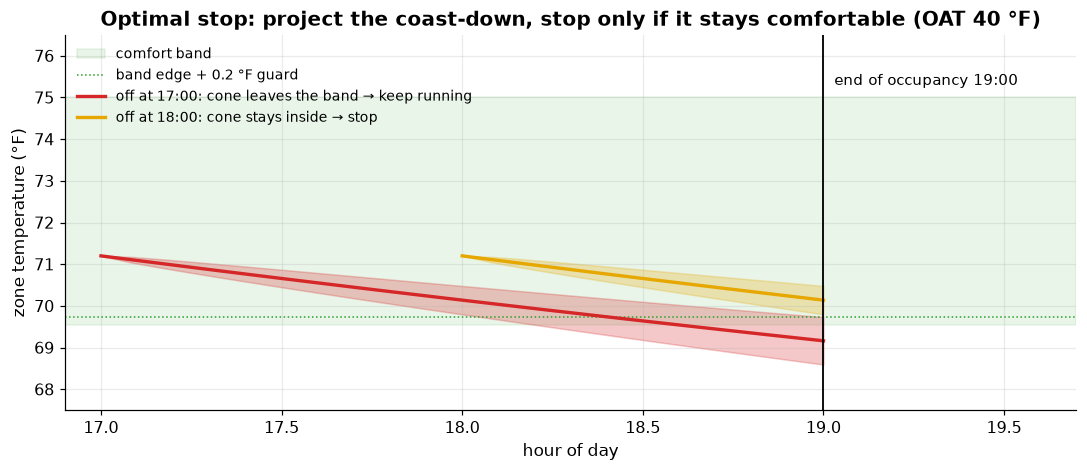

stop at 17:00 for 2 h? False | stop for the last 60 min? True


In [16]:
class FirstOrderCoast:
    """1R1C coast model learned by recursive least squares on AHU-off intervals."""
    def __init__(self, lam=0.999, k=2.0, struct=0.15):
        self.th, self.P, self.lam, self.k, self.struct, self.res = np.array([0.05, 0.0, 0.3]), np.diag([0.01, 1.0, 1.0]), lam, k, struct, []
    def update(self, t0, t1, oat, minutes, occupied):
        x = np.array([oat - t0, 1.0, float(occupied)]); y = (t1 - t0) / (minutes / 60)   # observed drift, °F/h
        Px = self.P @ x; K = Px / (self.lam + x @ Px); err = y - x @ self.th
        self.th = self.th + K * err; self.P = (self.P - np.outer(K, Px)) / self.lam; self.res.append(err)
    def bounds(self, temp, oat, minutes, occupied=True):
        a, b, c = self.th; a = max(a, 1e-4); h = minutes / 60
        t_inf = oat + (b + (c if occupied else 0.0)) / a
        mid = t_inf + (temp - t_inf) * math.exp(-a * h)
        r = np.asarray(self.res[-500:]); sigma = 1.4826 * np.median(np.abs(r - np.median(r))) if len(r) >= 12 else 1.0
        unc = (self.k * sigma / math.sqrt(max(1.0, minutes / 5)) + self.struct) * h
        return mid - unc, mid + unc

def should_stop(model, temp, oat, minutes_left, heat_sp=69.53, cool_sp=75.0, guard=0.2):
    lo, hi = model.bounds(temp, oat, minutes_left)
    return lo >= heat_sp + guard and hi <= cool_sp - guard

# Demo: learn from synthetic off-hours drift of a zone with a = 0.08 /h, b = 0.6 °F/h, c = 0.9 °F/h, then project.
rng = np.random.default_rng(7); true = (0.08, 0.6, 0.9); m = FirstOrderCoast(); T = 70.0
for i in range(600):                     # ~2 days of 5-minute off intervals
    oat, occ = 45 + 10 * math.sin(i / 288 * 2 * math.pi), (i % 288) > 200
    dT = (true[0] * (oat - T) + true[1] + true[2] * occ) * (5 / 60) + rng.normal(0, 0.03)
    m.update(T, T + dT, oat, 5, occ); T = float(np.clip(T + dT, 62, 78))
print("learned a, b, c =", np.round(m.th, 3), " true =", true)

fig, ax = plt.subplots(figsize=(10, 4.4)); T0, oat = 71.2, 40.0
ax.axhspan(69.53, 75.0, color="#2ca02c", alpha=0.10, label="comfort band")
ax.axhline(69.53 + 0.2, color="#2ca02c", ls=":", lw=1, label="band edge + 0.2 °F guard")
for t_off, col, lab in [(17.0, "#d62728", "off at 17:00: cone leaves the band → keep running"),
                        (18.0, STOP_COLORS["first_order_coast"], "off at 18:00: cone stays inside → stop")]:
    t = np.arange(0, (19 - t_off) * 60 + 1, 5)
    lh = np.array([m.bounds(T0, oat, max(x, 1e-6)) for x in t])
    ax.fill_between(t_off + t / 60, lh[:, 0], lh[:, 1], color=col, alpha=0.25)
    ax.plot(t_off + t / 60, lh.mean(axis=1), color=col, lw=2.2, label=lab)
ax.axvline(19, color="k", lw=1.2); ax.text(19.03, 75.3, "end of occupancy 19:00", fontsize=9.5)
ax.set_xlabel("hour of day"); ax.set_ylabel("zone temperature (°F)"); ax.set_ylim(67.5, 76.5); ax.set_xlim(16.9, 19.7)
ax.set_title("Optimal stop: project the coast-down, stop only if it stays comfortable (OAT 40 °F)")
ax.legend(loc="upper left", fontsize=9); plt.tight_layout(); plt.show()
print("stop at 17:00 for 2 h?", should_stop(m, T0, oat, 120), "| stop for the last 60 min?", should_stop(m, T0, oat, 60))

### Evaluation

In the main runs every algorithm used a 0.9 °F stop guard, the same as the NeurIPS v6 controller. With that guard the stop
algorithms **almost never fired** (under 0.4 % of AHU-days): the G36 sequence holds zones within about 0.7 °F of the band edge
in the late afternoon.
So we ran a dedicated stop experiment: the same fixed 120-minute start in every run, a 0.2 °F guard, four stop algorithms,
one building in four climates (Atlanta, Denver, Minneapolis, Phoenix), all 30 days scored.

,AHU-days,days stopped early %,early-stop min (mean),restarts/day,unmet last 3 h (°F·min/zone),evening energy saved %,reward gain
stop,,,,,,,
First-order coast (ours),336,5.65,0.39,0.43,12.56,3.01,-0.009
Constant drift 0.35 °F/h,336,2.08,0.12,0.69,17.58,5.71,-0.050
G36 recovery-rate proxy,336,0.60,0.04,0.00,11.68,-0.05,+0.004
No early stop,336,0.00,0.00,0.00,11.82,0.00,+0.000


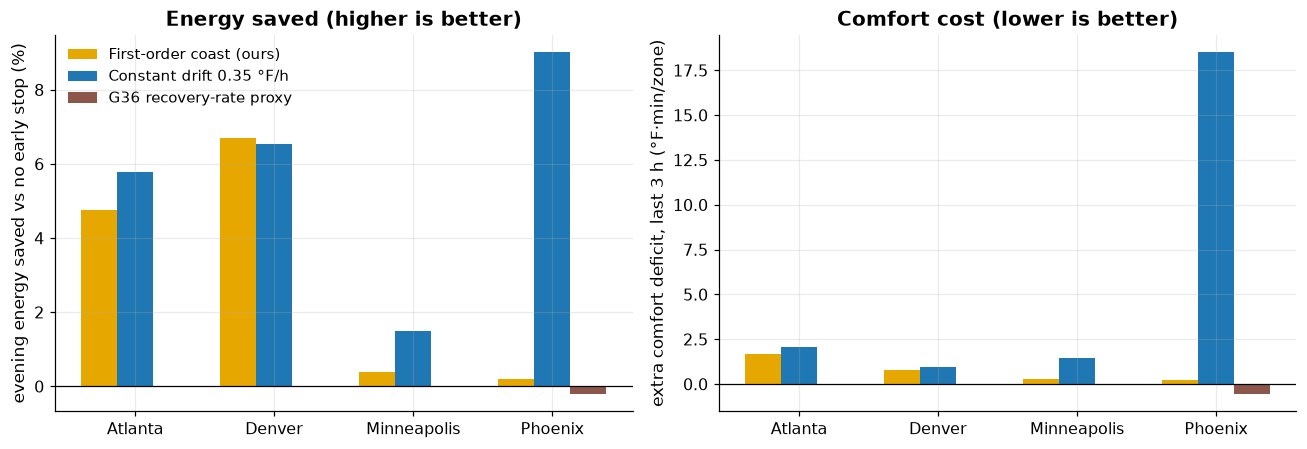

In [17]:
g = SD.groupby(["scenario", "date", "stop"], as_index=False)[["evening_energy", "evening_reward"]].mean()
b0 = g[g.stop == "no_early_stop"].rename(columns={"evening_energy": "e0", "evening_reward": "r0"}).drop(columns="stop")
g = g.merge(b0, on=["scenario", "date"]); g["saved"] = 100 * (g.e0 - g.evening_energy) / g.e0; g["dr"] = g.evening_reward - g.r0
g["city"] = g.scenario.str.split("/").str[1].str.split("_").str[0]
SA["stop_unmet_f"] = SA.stop_unmet * K2F
def stop_table(by):
    s = SA.groupby(by).agg(days=("stop_lead", "size"), stopped=("stop_lead", lambda x: 100 * (x > 0).mean()),
                           early_min=("stop_lead", "mean"), restarts=("restarts", "mean"), unmet=("stop_unmet_f", "mean"))
    return s.join(g.groupby(by).agg(saved=("saved", "mean"), reward=("dr", "mean")))
ST = stop_table(["stop"]).loc[["first_order_coast", "vavrl_const_drift", "v6", "no_early_stop"]]
display(ST.rename(index=STOP_NAMES, columns={"days": "AHU-days", "stopped": "days stopped early %", "early_min": "early-stop min (mean)",
        "restarts": "restarts/day", "unmet": "unmet last 3 h (°F·min/zone)", "saved": "evening energy saved %", "reward": "reward gain"})
        .pipe(lambda t: t.style.format(F(t, "{:.2f}", **{"AHU-days": "{:,.0f}", "reward gain": "{:+.3f}"}))).set_caption("Optimal stop, all four climates"))

SC = stop_table(["stop", "city"]).reset_index()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
cities = sorted(SC.city.unique()); x = np.arange(len(cities)); wd = 0.26
for i, k in enumerate(["first_order_coast", "vavrl_const_drift", "v6"]):
    s = SC[SC.stop == k].set_index("city").reindex(cities)
    base = SC[SC.stop == "no_early_stop"].set_index("city").reindex(cities)
    a1.bar(x + (i - 1) * wd, s.saved, wd, color=STOP_COLORS[k], label=STOP_NAMES[k])
    a2.bar(x + (i - 1) * wd, s.unmet - base.unmet, wd, color=STOP_COLORS[k], label=STOP_NAMES[k])
for ax, yl, tt in [(a1, "evening energy saved vs no early stop (%)", "Energy saved (higher is better)"),
                   (a2, "extra comfort deficit, last 3 h (°F·min/zone)", "Comfort cost (lower is better)")]:
    ax.set_xticks(x); ax.set_xticklabels([c.title() for c in cities]); ax.set_ylabel(yl); ax.set_title(tt); ax.axhline(0, color="k", lw=0.8)
a1.legend(); plt.tight_layout(); plt.show()

**Verdict.** The **first-order coast** is the best stop algorithm on the worst case. It stops early on about 6 % of
AHU-days and saves **3.0 % of evening energy** for **+0.7 °F·min/zone** of extra comfort deficit, with a reward change of only
−0.009. The constant-drift rule (0.35 °F/h, a common rule of thumb) saves more energy (5.7 %), but in Phoenix it turns the
AHU off on hot afternoons and the comfort deficit jumps by about 18 °F·min/zone (reward −0.05). The G36 recovery-rate proxy
almost never stops. The opportunity is real but small: G36 already runs these buildings tightly in the evening.

<a id="board"></a>
## 9. Head-to-head leaderboard and recommendation

All start algorithms, all 22 scenarios (6 buildings × 6 climates, including two Minneapolis weather years that are not in
the simulator's training set). Savings beyond schedule needs the three fixed-schedule anchors, which were run on 12 of the
scenarios; reward regret uses all of them. Algorithms run on fewer scenarios (PNNL M1-M3 and two other baselines ran on
6 of them) are marked, because their worst case isn't comparable.

In [18]:
L = P.groupby("start").agg(scenarios=("scenario", "nunique"), beyond=("beyond", "mean"), beyond_worst=("beyond", "min"),
                           regret=("regret", "mean"), regret_worst=("regret", "min"))
L = L.join(score(["start"])[["late_pct", "unmet", "saved_pct"]]).sort_values("regret", ascending=False)
LB = L.rename(index=NAMES, columns={"scenarios": "scenarios", "beyond": "savings beyond schedule % (mean)",
              "beyond_worst": "… worst scenario", "regret": "reward regret (mean)", "regret_worst": "… worst scenario ",
              "late_pct": "late % (1 °F tol.)", "unmet": "unmet (°F·min/zone)", "saved_pct": "energy saved vs fixed 120 %"})
def hl(row):
    return ["background-color: #fff3c4; font-weight: bold" if row.name == NAMES["m0_linear_ema"] else "" for _ in row]
display(LB.style.format(F(LB, "{:.2f}", scenarios="{:.0f}", **{"reward regret (mean)": "{:.3f}", "… worst scenario ": "{:.3f}"}), na_rep="–").apply(hl, axis=1)
        .background_gradient(subset=["savings beyond schedule % (mean)", "reward regret (mean)"], cmap="RdYlGn")
        .set_caption("Start leaderboard, sorted by mean reward regret (0 = best in every scenario)"))

,scenarios,savings beyond schedule % (mean),… worst scenario,reward regret (mean),… worst scenario,late % (1 °F tol.),unmet (°F·min/zone),energy saved vs fixed 120 %
start,,,,,,,,
Fixed 60 min,12,0.00,0.00,-0.022,-0.086,57.72,51.15,9.23
PNNL M4 · exponential,22,-0.40,-9.48,-0.033,-0.174,45.15,64.50,13.82
G36 recovery learner (NeurIPS v7),22,-0.83,-6.04,-0.062,-0.243,46.85,55.89,4.19
Linear-rate EMA (ours),22,1.60,-0.78,-0.065,-0.259,42.65,55.55,8.54
Fixed 120 min,22,0.00,-0.00,-0.081,-0.260,33.90,49.03,0.00
G36 learned rate (NeurIPS v6),22,0.17,-1.49,-0.082,-0.260,34.00,49.10,0.21
PNNL deployed (median of M1-M4),22,1.76,-0.61,-0.119,-0.470,40.00,50.63,3.70
SGD regression,6,0.11,-1.74,-0.133,-0.447,48.48,57.90,3.98
Robust RLS,22,0.21,-4.22,-0.142,-0.513,40.80,50.14,3.23


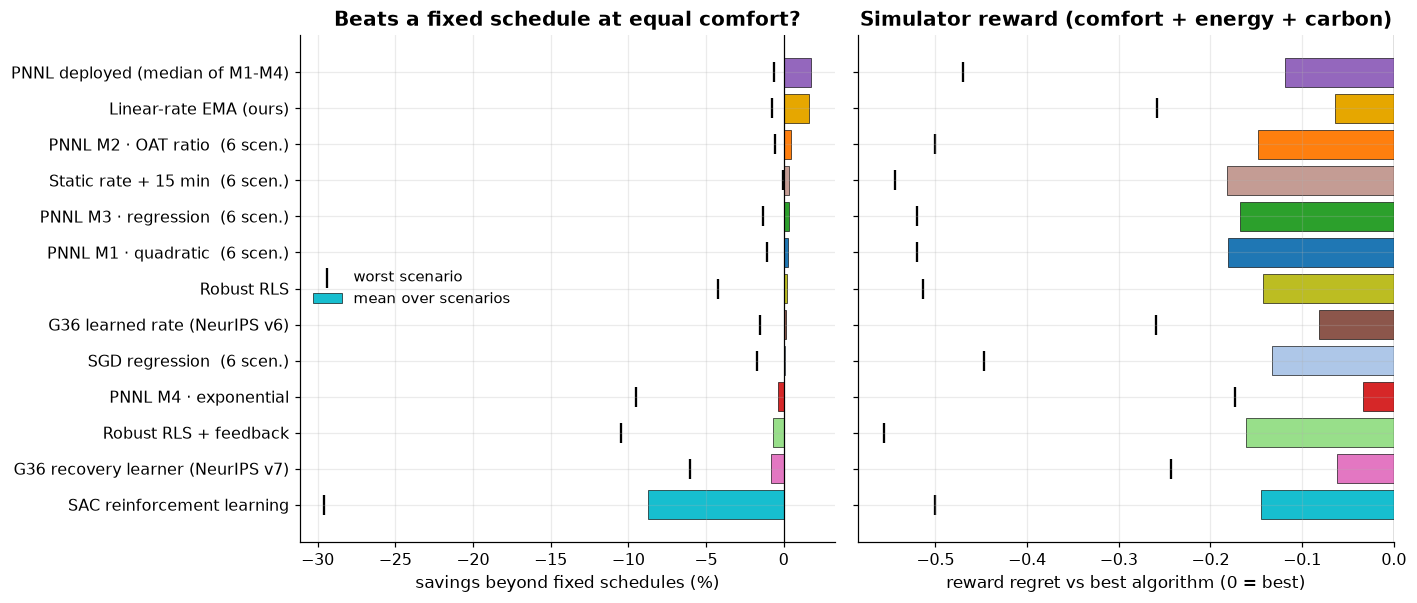

In [19]:
keys = [k for k in L.index if k not in ("fixed_60", "fixed_120", "fixed_180")]
keys = sorted(keys, key=lambda k: L.loc[k, "beyond"] if np.isfinite(L.loc[k, "beyond"]) else -99)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.6), sharey=True)
y = np.arange(len(keys))
for ax, col, worst, xl in [(a1, "beyond", "beyond_worst", "savings beyond fixed schedules (%)"),
                           (a2, "regret", "regret_worst", "reward regret vs best algorithm (0 = best)")]:
    ax.barh(y, L.loc[keys, col], color=[COLORS[k] for k in keys], edgecolor="k", lw=0.4, label="mean over scenarios")
    ax.scatter(L.loc[keys, worst], y, marker="|", s=160, color="k", label="worst scenario")
    ax.axvline(0, color="k", lw=0.8); ax.set_xlabel(xl)
a1.set_yticks(y); a1.set_yticklabels([NAMES[k] + ("  (6 scen.)" if L.loc[k, "scenarios"] < 10 else "") for k in keys])
a1.set_title("Beats a fixed schedule at equal comfort?"); a2.set_title("Simulator reward (comfort + energy + carbon)")
a1.legend(loc="center left"); plt.tight_layout(); plt.show()

### The Monday problem

The PNNL paper found all four models did poorly on Mondays: after a weekend setback the building is cold-soaked and
recovers slower than any weekday taught the model. Same here: lateness on the first morning after a weekend vs. other days.

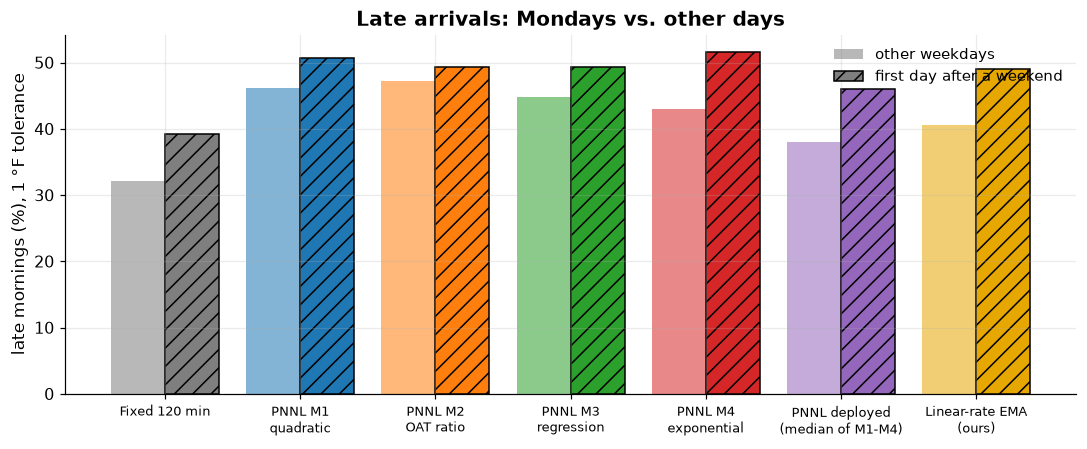

In [20]:
K = ["fixed_120", "pnnl_m1_quadratic", "pnnl_m2_oat_ratio", "pnnl_m3_regression", "pnnl_m4_exponential",
     "pnnl_deployed_median_split", "m0_linear_ema"]
MW = A[A.start.isin(K)].groupby(["start", "post_weekend"]).late_tol.apply(lambda x: 100 * (x > 0).mean()).unstack()
fig, ax = plt.subplots(figsize=(10, 4.2)); x = np.arange(len(K))
ax.bar(x - 0.2, MW.loc[K, False], 0.4, color=[COLORS[k] for k in K], alpha=0.55, label="other weekdays")
ax.bar(x + 0.2, MW.loc[K, True], 0.4, color=[COLORS[k] for k in K], edgecolor="k", hatch="//", label="first day after a weekend")
ax.set_xticks(x); ax.set_xticklabels([NAMES[k].replace(" · ", "\n").replace(" (", "\n(") for k in K], fontsize=8.5)
ax.set_ylabel("late mornings (%), 1 °F tolerance"); ax.set_title("Late arrivals: Mondays vs. other days"); ax.legend()
plt.tight_layout(); plt.show()

<div style="border-left: 6px solid #e6a700; background: #fff8e1; padding: 12px 18px; border-radius: 4px;">

### Recommendation
* **Optimal start: use the linear-rate EMA** ($\widehat{t} = \Delta T / R$, $w = 0.2$), clamped between 10 min and your
  current fixed lead, with a small post-weekend margin. Of the algorithms run on all 22 scenarios, it is the only one with
  **positive mean savings beyond schedule (+1.60 %), a worst case under 1 % (−0.78 %), and top-tier reward regret
  (−0.065 mean, −0.26 worst)**. PNNL's deployed median is a respectable runner-up (+1.76 % / −0.61 %) with worse reward
  regret (−0.12 / −0.47). Avoid PNNL Model 4 on its own: its average reward is good, but its comfort and worst case are the
  worst of the field.
* **Optimal stop: use the first-order coast model** with a tight guard (0.2 °F) and a restart rule. Expect a few percent of
  evening energy, mostly in mild weather.
* **Mondays need help.** Every learner is late more often on the first day after a weekend (EMA 40.5 % → 49.0 %, PNNL
  median 38.0 % → 46.0 %, fixed 120 min 32.1 % → 39.2 %). Keep a separate post-weekend rate, or add 15-30 min on those days.
* A note on the reward: a fixed 60-minute start has the best mean reward regret (−0.02), because the simulator's reward
  prices energy above early-morning comfort. It ran on 12 of the 22 scenarios and is late on 58 % of mornings. That's why
  we don't rank on reward alone.
</div>

<a id="end"></a>
## 10. Takeaways, limitations, use it on your own building, references

### Takeaways
1. **Score optimal start on the energy-vs-comfort trade-off, not on energy alone.** Any algorithm can "save energy" by starting
   late. The question is whether it beats a fixed schedule that delivers the same comfort.
2. **Simple wins.** A one-parameter learned rate beat four published models and an RL agent on robustness. Most of the
   sophistication in the PNNL models (quadratic terms, OAT ratios, exponential fits) adds variance in a building that
   recovers in 10-20 minutes.
3. **The PNNL ensemble idea is sound.** Taking the median of four models was the second-best start strategy, and far safer
   than any single PNNL model.
4. **Optimal stop is a small, safe win** when the drift model has honest uncertainty bounds. Fixed drift-rate rules are risky in
   hot climates.
5. **Mondays are still the hard problem,** exactly as the PNNL field study found.

### Limitations
* **One simulator.** The NeurIPS buildings have strong, fast-recovering VAV systems with reheat; recovery is often 10-20 min.
  Small buildings with rooftop units (the PNNL paper's setting) recover much more slowly, which gives optimal start more room.
* **Online learning from day 1, 30 days per run.** Long-run seasonal behaviour isn't tested.
* **Lateness is measured on the last recoverable zone of each AHU.** Zones that never reach the band (capacity-limited in
  Fairbanks and Minneapolis January) are excluded from lateness but still count in the comfort deficit.
* **The stop experiment covers one building in four climates** with a fixed 120-min start.

### Use it on your own building
1. From your trend logs, extract each morning's warm-up start, the critical zone's temperature trajectory, its setpoint and OAT
   into a table shaped like `recovery_events.csv.gz` / `recovery_traces.csv.gz` (°F, 5-minute samples).
2. Run `replay(LinearRateEMA)` (and the PNNL models) on it and check `replay_stats`: MAE and the share of late starts.
3. Deploy the linear-rate EMA with a clamp (start no earlier than your current schedule, no later than 10 min before
   occupancy) and a post-weekend margin. Log arrival error every morning and keep the fixed schedule as a fallback.
4. For optimal stop, log 5-minute zone temperature while the AHU is off, fit `FirstOrderCoast`, and only allow early stop
   with a guard you're comfortable with (0.2-0.5 °F) and a restart rule.

### References
* W. Kim, M. G. Yu, R. G. Lutes, S. Katipamula. *Implementation and validation of optimal start control strategy for air
  conditioners and heat pumps.* Applied Thermal Engineering 257 (2024) 124256. https://doi.org/10.1016/j.applthermaleng.2024.124256
* Google Smart Buildings simulator (`sbsim`), used by the NeurIPS 2026 Smart Buildings challenge: https://github.com/google/sbsim
* ASHRAE Guideline 36, *High-Performance Sequences of Operation for HVAC Systems.*
* Benchmark code, raw traces and the earlier lessons live in the repository's `archive/pre-strip-2026-11-17` tag:
  https://github.com/bbartling/hvac-optimal-start-math-playground/tree/archive/pre-strip-2026-11-17